# Chi-square minimization for spectrophotometric data

Forward modeling of an SED assembled using multiple spectra and photometry by minimizing the chi-square statistics between the data and atmospheric models.

In [1]:
import seda # import the seda package
import importlib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import MultipleLocator, FormatStrFormatter, AutoMinorLocator, StrMethodFormatter, NullFormatter
from astropy.io import fits, ascii


    SEDA v0.8.10.dev48 package imported


## Read the data

As an example here, let's read:
- **Spectra**: the near-infrared IRTF/SpeX, the mid-infrared JWST/NIRSpec, and the mid-infrared Spitzer/IRS spectra for the T8 (~750 K) brown dwarf 2MASS J04151954-0935066 in [Burgasser et al. (2004)](https://ui.adsabs.harvard.edu/abs/2004AJ....127.2856B/abstract), [Alejandro Merchan et al. (2025)](https://ui.adsabs.harvard.edu), and [Suárez & Metchev (2022)](https://ui.adsabs.harvard.edu/abs/2022MNRAS.513.5701S/abstract), respectively.

- **Photometry**: near- and mid-infrared magnitudes from different surveys (2MASS, Spitzer/IRAC, WISE, and JWST/MIRI) for the T8 (~750 K) brown dwarf 2MASS J04151954-0935066, as compiled in [Alejandro Merchan et al. (2025)](https://ui.adsabs.harvard.edu/abs/2025ApJ...989...80A/abstract):

### Spectra

SpeX spectrum:

In [2]:
# path to the SEDA package
path_seda = Path(seda.__file__).resolve().parents[1]

# SpeX spectrum
SpeX_name = (path_seda / 'docs' / 'notebooks' / 
             'data' / '0415-0935_IRTF_SpeX.dat')
SpeX = ascii.read(SpeX_name)
wl_SpeX = SpeX['wl(um)'] # um 
flux_SpeX = SpeX['flux(erg/s/cm2/A)'] # erg/s/cm2/A
eflux_SpeX = SpeX['eflux(erg/s/cm2/A)'] # erg/s/cm2/A

Read JWST NIRSpec spectrum

In [3]:
NIRSpec_name = (path_seda / 'docs' / 'notebooks' / 
             'data' / '0415-0935_NIRSpec_spectrum.dat')
NIRSpec = ascii.read(NIRSpec_name)
wl_NIRSpec = NIRSpec['wl(um)'] # um 
flux_NIRSpec = NIRSpec['flux(Jy)'] # Jy
eflux_NIRSpec = NIRSpec['eflux(Jy)'] # Jy

# convert NIRSpec fluxes from Jy to erg/s/cm2/A
out_convert_flux = seda.synthetic_photometry.convert_flux(wl=wl_NIRSpec, 
                                                          flux=flux_NIRSpec, 
                                                          eflux=eflux_NIRSpec, 
                                                          unit_in='Jy', 
                                                          unit_out='erg/s/cm2/A')
flux_NIRSpec = out_convert_flux['flux_out'] # in erg/s/cm2/A
eflux_NIRSpec = out_convert_flux['eflux_out'] # in erg/s/cm2/A

# remove a few negative fluxes and edge points
mask = (flux_NIRSpec>0) & ((wl_NIRSpec<3.68) | (wl_NIRSpec>3.79))
wl_NIRSpec = wl_NIRSpec[mask]
flux_NIRSpec = flux_NIRSpec[mask]
eflux_NIRSpec = eflux_NIRSpec[mask]

Read IRS spectrum:

In [4]:
IRS_name = (path_seda / 'docs' / 'notebooks' / 
             'data' / '0415-0935_IRS_spectrum.dat')
IRS = ascii.read(IRS_name)
wl_IRS = IRS['wl(um)'] # in um
flux_IRS = IRS['flux(Jy)'] # in Jy
eflux_IRS = IRS['eflux(Jy)'] # in Jy

# convert IRS fluxes from Jy to erg/s/cm2/A
out_convert_flux = seda.synthetic_photometry.convert_flux(wl=wl_IRS, 
                                                          flux=flux_IRS, 
                                                          eflux=eflux_IRS, 
                                                          unit_in='Jy', 
                                                          unit_out='erg/s/cm2/A')
flux_IRS = out_convert_flux['flux_out'] # in erg/s/cm2/A
eflux_IRS = out_convert_flux['eflux_out'] # in erg/s/cm2/A

### Photometry

In [5]:
# path to the SEDA package
path_seda = Path(seda.__file__).resolve().parents[1]

# read table with photometry
phot_file = (path_seda / 'docs' / 'notebooks' / 
             'data' / '0415-0935_photometry.dat')
photometry = ascii.read(phot_file)

# keep columns with magnitudes of interest
photometry.remove_column('WISE_designation') # remove only columns without photometry

# convert table with photometry to a dictionary with three keys: filters, photometry, and uncertainties
# save output dictionary as a fancy ascii table in the seda directory "data"
# the output table can be open using "seda.read_prettytable"
table_name = (path_seda / 'docs' / 'notebooks' / 'data' /
              '0415-0935_photometry_prettytable.dat')
out = seda.utils.convert_photometric_table(photometry, save_table=True, 
                                           table_name=table_name)
phot = out['phot']
ephot = out['ephot']
filters = out['filters']

Convert magnitudes into fluxes:

In [7]:
# mag to flux
out_mag_to_flux = seda.synthetic_photometry.mag_to_flux(mag=phot, emag=ephot, filters=filters, 
                                                        flux_unit='erg/s/cm2/A')
#                                                       flux_unit='Jy')
flux = out_mag_to_flux['flux'] # in erg/s/cm2/A
eflux = out_mag_to_flux['eflux'] # in erg/s/cm2/A
wl_eff = out_mag_to_flux['lambda_eff_SVO(um)'] # effective wavelength in um
width_eff = out_mag_to_flux['width_eff_SVO(um)'] # effective width in um
filters = out_mag_to_flux['filters']

### Plot SED
Verify everything looks okay:

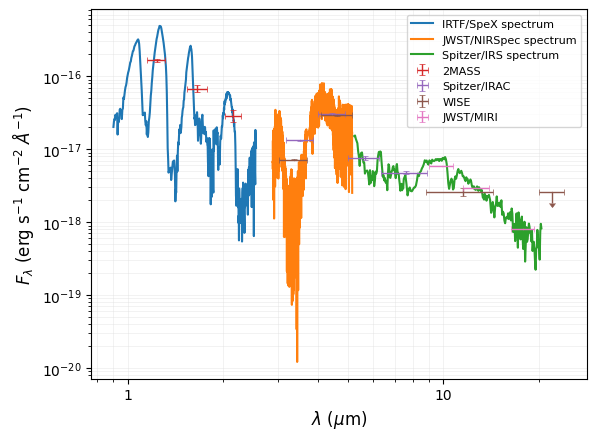

In [8]:
fig, ax = plt.subplots()

# plot spectra
plt.plot(wl_SpeX, flux_SpeX, label='IRTF/SpeX spectrum')
plt.plot(wl_NIRSpec, flux_NIRSpec, label='JWST/NIRSpec spectrum')
plt.plot(wl_IRS, flux_IRS, label='Spitzer/IRS spectrum')

# plot photometry
# select 2MASS magnitudes
mask_2MASS = ['2MASS' in filt for filt in filters]
ax.errorbar(wl_eff[mask_2MASS], flux[mask_2MASS], xerr=width_eff[mask_2MASS]/2, 
            yerr=eflux[mask_2MASS], fmt='.', markersize=1., capsize=2, 
            elinewidth=1.0, markeredgewidth=0.5, label='2MASS')

# select IRAC magnitudes
mask_IRAC = ['IRAC' in filt for filt in filters]
ax.errorbar(wl_eff[mask_IRAC], flux[mask_IRAC], xerr=width_eff[mask_IRAC]/2, 
            yerr=eflux[mask_IRAC], fmt='.', markersize=1., capsize=2, 
            elinewidth=1.0, markeredgewidth=0.5, label='Spitzer/IRAC')

# select WISE magnitudes
mask_WISE = ['WISE' in filt for filt in filters]
# handle upper limits
uplims = (ephot==0) * 1 # upper limits (null errors) indicated by 1
eflux[eflux==0] = 0.3*flux[eflux==0] # size of the arrow indicating upper limits
# plot WISE with upper limits
ax.errorbar(wl_eff[mask_WISE], flux[mask_WISE], xerr=width_eff[mask_WISE]/2, 
            yerr=eflux[mask_WISE], fmt='.', markersize=1., capsize=2, 
            elinewidth=1.0, markeredgewidth=0.5, label='WISE',
            uplims=uplims[mask_WISE])

# select MIRI magnitudes
mask_JWST = ['JWST' in filt for filt in filters]
ax.errorbar(wl_eff[mask_JWST], flux[mask_JWST], xerr=width_eff[mask_JWST]/2, 
            yerr=eflux[mask_JWST], fmt='.', markersize=1., capsize=2, 
            elinewidth=1.0, markeredgewidth=0.5, label='JWST/MIRI')

ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())
plt.xscale('log')
plt.yscale('log')
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:.0f}'))

ax.grid(True, which='both', color='gainsboro', linewidth=0.5, alpha=0.5)
ax.legend(fontsize=8)

plt.xlabel(r'$\lambda\ (\mu$m)', size=12)
plt.ylabel(r'$F_\lambda\ ($erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$)', size=12)

plt.show()

## Load input data

Look at the input parameters [here](https://seda.readthedocs.io/en/latest/api.html#seda.input_parameters.InputData).

For any SEDA function, we can also see the function description directly on the notebook with the command ``help()``, e.g.:

``help(seda.input_parameters.InputData)``

In [9]:
# spectra
#--------
# wavelenghts
wl_spectra = [wl_SpeX, wl_NIRSpec, wl_IRS] # in um
# fluxes
flux_spectra = [flux_SpeX, flux_NIRSpec, flux_IRS] # in erg/s/cm2/A
# flux uncertainties
eflux_spectra = [eflux_SpeX, eflux_NIRSpec, eflux_IRS] # in erg/s/cm2/A
# specify flux units
flux_unit = 'erg/s/cm2/A'

# resolution of each input spectrum (used to convolve the model spectra)
res = [100, 2700, 100] # SpeX, NIRSpec, IRS

# photometry
#-----------
# input photometry
phot = phot
ephot = ephot
filters = filters
phot_unit = 'mag'

# distance to the target (optional and used to derive a radius)
distance = 5.71 # pc (parallax=175.2+-1.7; Dupuy-Liu2012)
edistance = 0.06 # pc

# load all the input data parameters
my_data = seda.input_parameters.InputData(wl_spectra=wl_spectra, 
                                          flux_spectra=flux_spectra, 
                                          eflux_spectra=eflux_spectra, 
                                          flux_unit=flux_unit, 
                                          res=res, phot=phot, ephot=ephot, 
                                          filters=filters, phot_unit=phot_unit, 
                                          fit_photometry=True, 
                                          distance=distance, edistance=edistance)

Null photometric errors for ['WISE/WISE.W4'] magnitudes, so they will be discarded.

   Input data loaded successfully:
      3 spectra
      13 magnitudes


Download (if not yet) the atmospheric models you want to use. 

Use the commands below to see the available atmospheric models, the links to download them, and other relevant information from models. You can read more about the model [here](https://seda.readthedocs.io/en/latest/overview.html#available-atmospheric-models).

Also consider [this tutorial](https://seda.readthedocs.io/en/latest/notebooks/tutorial_models_examination.html) to explore the free parameters in the models and their coverage.

In [10]:
# available atmospheric models
seda.models.Models().available_models

['ATMO2020',
 'BT-Settl',
 'LB23',
 'LOWZ',
 'SAND',
 'SM08',
 'Sonora_Bobcat',
 'Sonora_Cholla',
 'Sonora_Diamondback',
 'Sonora_Elf_Owl',
 'Sonora_Flame_Skimmer']

In [11]:
# some parameters of interest from a selected model
model = 'LB23'
print(seda.models.Models(model).ref) # reference
print(seda.models.Models(model).ADS) # link to paper
print(seda.models.Models(model).download) # link to download the models
seda.models.Models(model).params_unique # coverage of free parameters in the grid

Lacy & Burrows (2023)
https://ui.adsabs.harvard.edu/abs/2023ApJ...950....8L/abstract
https://zenodo.org/records/7779180


{'Teff': array([250., 275., 300., 325., 350., 375., 400., 425., 450., 475., 500.,
        525., 550., 575., 600., 650., 700., 750., 800.]),
 'logg': array([3.5 , 3.75, 4.  , 4.25, 4.5 , 4.75, 5.  ]),
 'Z': array([-0.5,  0. ,  0.5]),
 'logKzz': array([6.]),
 'Hmix': array([0.01, 0.1 , 1.  ])}

## Load model grid options

Look at the input parameters [here](https://seda.readthedocs.io/en/latest/api.html#seda.input_parameters.ModelOptions).

In [9]:
# select the atmospheric models of interest
model = 'LB23'

# path to the directory or directories containing the model spectra
# (update it to your own path)
my_path = '/home/gsuarez/TRABAJO/MODELS/atmosphere_models/'
model_dir = my_path+'LB2023_extended/LB2023_extended/Spectra/'

# set parameter ranges to select a grid subset
# when a free parameter range is not specified, the whole grid range will be considered
params_ranges = {
    'Teff': [700, 900], # Teff range
    'logg': [4.0, 5.0] # logg range
}

# load model options
my_model = seda.input_parameters.ModelOptions(model=model, model_dir=model_dir, 
                                              params_ranges=params_ranges)


   Model options loaded successfully


**Tip:** If you plan to model several spectra from the same instrument (same resolution), you can save the convolved model spectra to reuse them and do subsequent fits much faster. For this, set the parameter ``path_save_spectra_conv`` in ``seda.ModelOptions`` above to a folder path where you want to store the convolved spectra. Once the spectra are stored, the next time you run the code just replace ``model_dir`` by the path you used in ``path_save_spectra_conv`` and set ``skip_convolution=True`` to avoid the model convolution. This was implemented thanks to this [issue](https://github.com/suarezgenaro/seda/issues/14).

## Load chi-square fit options

Look at the input parameters [here](https://seda.readthedocs.io/en/latest/api.html#seda.input_parameters.Chi2Options).

Consider the default full wavelength range of each input spectrum for the fits. 
Otherwise, we can use the parameter ``fit_wl_range`` to set different fit ranges.

In [13]:
# choose a filename (optional) to save the sampling results as a pickle file
# it is convenient to set a non-default name when running 
# the code several times in the same folder to avoid overwriting results
chi2_pickle_file = f'{model}_chi2_minimization_spectrophotometry.pickle'
chi2_table_file = f'{model}_chi2_minimization_spectrophotometry.dat'

# load chi-square fit options
my_chi2 = seda.input_parameters.Chi2Options(my_data=my_data, my_model=my_model,
#                                             weight_label='none',
#                                             weight_label='dataset',
                                            chi2_pickle_file=chi2_pickle_file,
                                            chi2_table_file=chi2_table_file)


      135 model spectra
         user-constrained parameters:
             Teff range = [700, 900]
             logg range = [4.0, 5.0]
         model-constrained parameters:
            Z range = [-0.5, 0.5]
            logKzz range = [6.0, 6.0]
            Hmix range = [0.01, 1.0]


Reading, convolving, and resampling model spectra:   0%|          | 0/135 [00:00<?, ?it/s]


      13/13 selected input magnitudes within "fit_phot_range" or the model wavelength range


Deriving synthetic photometry from model spectra:   0%|          | 0/135 [00:00<?, ?it/s]


   Chi-square fit options loaded successfully
      elapsed time: 1.2 min


## Run chi-square fit

In [14]:
out_chi2 = seda.chi2_fit.chi2(my_chi2=my_chi2)


   Running chi-square fitting...


Minimizing chi-square:   0%|          | 0/135 [00:00<?, ?it/s]

      chi-square minimization results saved successfully

   Chi-square fit ran successfully
      elapsed time: 1.0 s


## Plot results

SED with the best three fits.

The pickle file generated by ``seda.chi2_fit`` and stored with the name ``my_chi2.chi2_pickle_file`` is the input file to make plots. We can provide the name by either using ``my_chi2.chi2_pickle_file`` (if ``my_chi2`` is in memory) or just typing it.

*Note that Elf Owl models do not cover wavelenghts longer than 15 microns.*

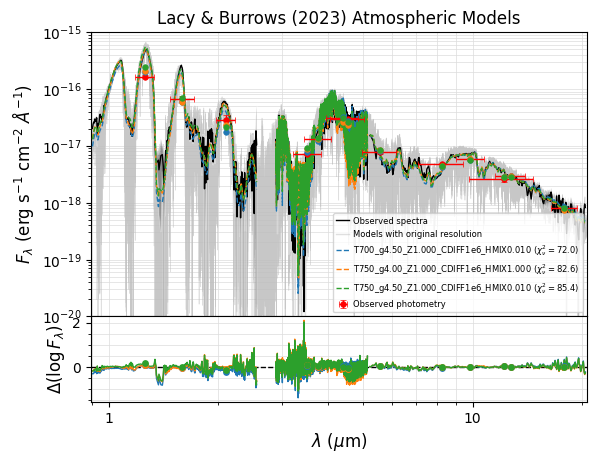

In [15]:
# plot wavelengths in logarithmic scale
chi2_pickle_file = 'LB23_chi2_minimization_spectrophotometry.pickle'
fig, ax = seda.plots.plot_chi2_fit(chi2_pickle_file, N_best_fits=3, xlog=True, 
                                   yrange=[1e-20, 1e-15], ori_res=True)

Zoom in on the SpeX spectrum:

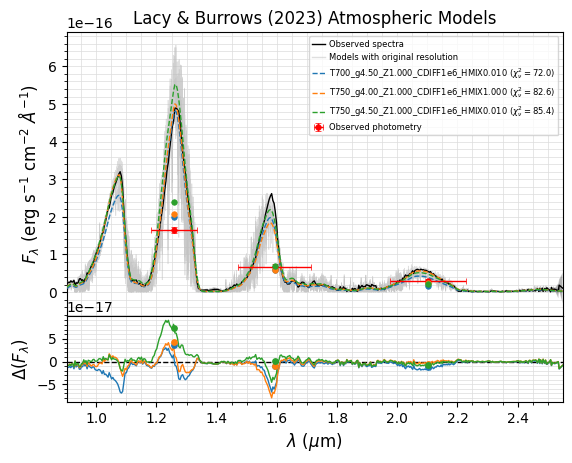

In [16]:
# plot fluxes in linear scale
fig, ax = seda.plots.plot_chi2_fit(chi2_pickle_file, N_best_fits=3, 
                                   xrange=[wl_SpeX.min(), wl_SpeX.max()],
                                   ori_res=True, ylog=False, save=False)

Zoom in on the NIRSpec spectrum:

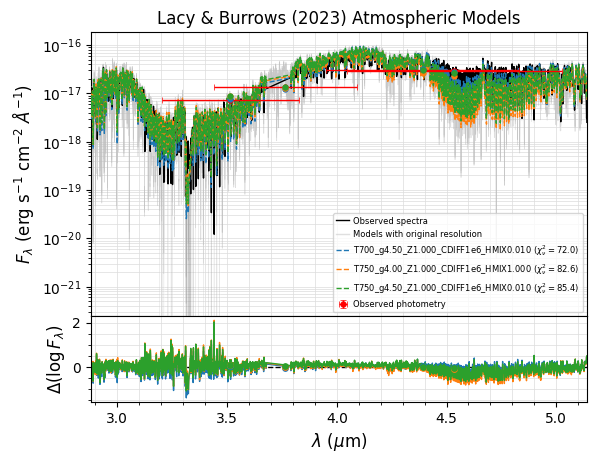

In [17]:
# plot fluxes in linear scale
fig, ax = seda.plots.plot_chi2_fit(chi2_pickle_file, N_best_fits=3,
                                   xrange=[wl_NIRSpec.min(), wl_NIRSpec.max()], 
                                   ori_res=True)

Zoom in on the IRS spectrum:

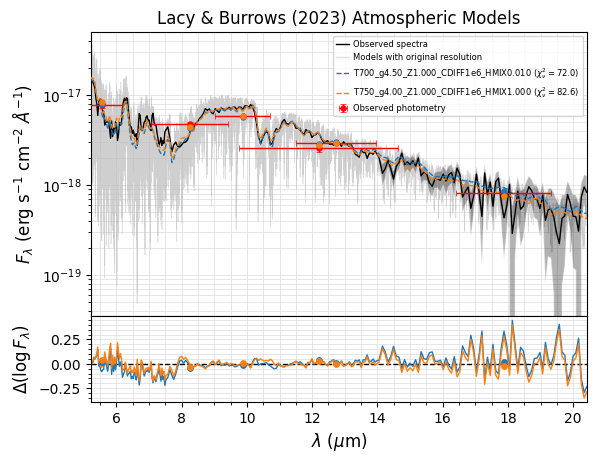

In [18]:
# plot fluxes in linear scale
fig, ax = seda.plots.plot_chi2_fit(chi2_pickle_file, N_best_fits=2,
                                   xrange=[wl_IRS.min(), wl_IRS.max()], 
                                   ori_res=True)

Reduced chi-square as a function of wavelength for the best three fits.

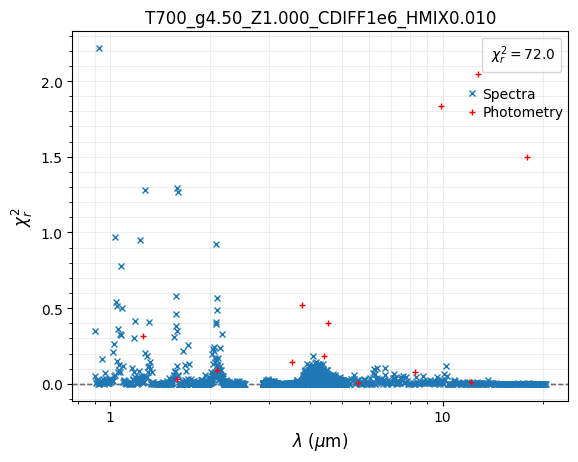

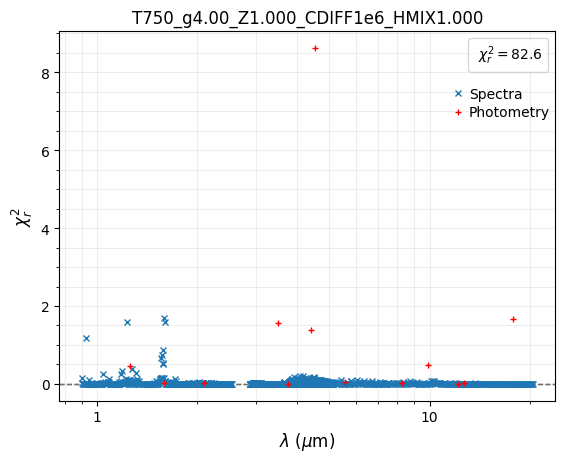

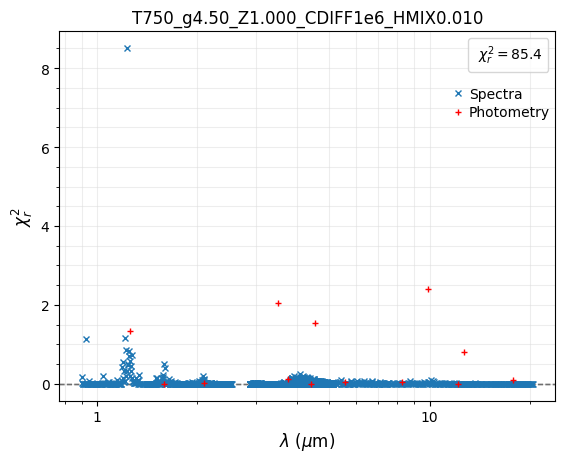

In [19]:
fig, ax = seda.plots.plot_chi2_red(chi2_pickle_file, N_best_fits=3, xlog=True)